In [1]:
import sys, json, pathlib, collections
sys.path.insert(0, str(pathlib.Path.cwd()))
import engine_api as ea, evaluation as ev
import design_helpers as dz
from design_helpers import PAL, display, HTML, plt, np
import pandas as pd
HOME = pathlib.Path.home()/"finetune_project"; DATA = pathlib.Path.cwd()/"data"; ENG = HOME/"engine"/"datos"
dz.setup()
dz.hero("Cross-receipt pattern reviewer", "From deterministic rules to our own model: the full story, step by step",
        "data → engine → its limit → fraud schemes → fine-tuning → results → governance → conclusions")

**How to read this notebook.** It follows the order in which we thought through the problem. Each section answers one question and ends with what we learned, including what went wrong. Everything shown is **computed here** with the real functions (the engine, the scoring); nothing is pasted by hand. Notebook `02` (engine) and the annexes have the details.

| # | Section question |
|---|---|
| 1 | What does the task ask for, what data do we have, and what are the correct answers? |
| 2 | What is the architecture, and does the engine agree with the answer key? |
| 3 | What can the engine NOT see? (the opportunity) |
| 4 | How do we generate fraud schemes that the engine lets through? |
| 5 | The catalog of 72 patterns |
| 6 | What data do we use to train and evaluate, and how do we avoid cheating ourselves? |
| 7 | Why Qwen3-4B and how do we train it? |
| 8 | Results against frontier models (with the independent test) |
| 9 | Governance and cost: why try our own model? |
| 10 | Honest conclusions and what comes next |

In [2]:
dz.banner(1, 'The task, the data and the correct answers', 'What did Oversight give us, and what is the correct answer for each receipt?')

**The task (Oversight):** an expense validator. Input: receipts with line items in several languages and 9 policy documents (**41 rules** with IDs). Output: for each receipt, `pass`, `review` or `flag`, citing the rule.

**The data:** 32 real receipts from the task (79 lines, 6 languages, 3 entities). Each line needs a **category** before rules can be applied (is it food, alcohol, a gift, equipment…?). That is the only part where an LLM is needed.

In [3]:
ANS = json.load(open(DATA/"oversight_answers.json"))
R = [json.loads(l) for l in open(ENG/"receipts_input.jsonl")]
n_lines = sum(len(a["lines"]) for a in ANS.values()); scored = {k: a for k, a in ANS.items() if a["in_scope"]}
cats_used = sorted({l["category"] for a in ANS.values() for l in a["lines"]})
dz.kpis([(len(ANS), "receipts", "each one ships WITH its correct answer", PAL["ft"]), (n_lines, "line items", "descriptions in 6 languages", PAL["muted"]), (len(cats_used), "categories used", "out of 21 in the taxonomy", PAL["muted"]),
         (len(scored), "scored by Oversight", "the 4 timing receipts are a stretch goal", PAL["good"])])

In [4]:
dz.callout('idea', 'Oversight shipped <code>receipts.jsonl</code> with, for every receipt, the <b>correct answer</b>: the category of each line, the exceptions it should raise (rule, severity, lines) and the final disposition, plus a <code>notes</code> field that explains the trap. The brief says to use them <b>only to evaluate</b>, never as input to the system or to a prompt. Below we only <i>look</i> at them to understand the data, and later to check the engine. Our fine-tuning data was also decontaminated against these 32 receipts.', 'Where the answers come from')

### 1.1 The correct dispositions: what a perfect system must output
Of the 32 receipts, Oversight scores 28 (**9 pass, 16 flag, 3 review**). Four receipts are out of scope: two halves of a split transaction (RCP-020, RCP-021), an overnight purchase (RCP-029) and a meal with no trip record (RCP-030).

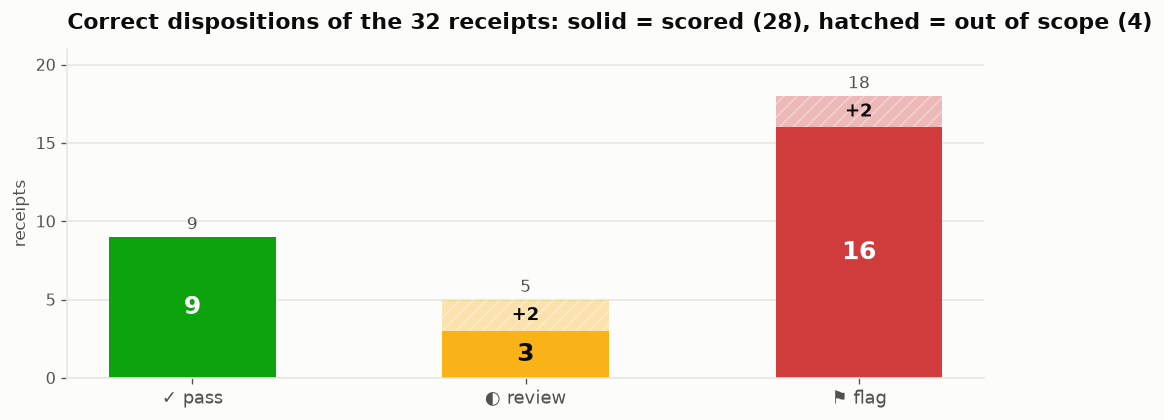

In [5]:
order = ["pass", "review", "flag"]; col = {"pass": PAL["good"], "review": PAL["warn"], "flag": PAL["crit"]}; icon = {"pass": "✓ pass", "review": "◐ review", "flag": "⚑ flag"}
cnt_in = collections.Counter(a["disposition"] for a in ANS.values() if a["in_scope"]); cnt_out = collections.Counter(a["disposition"] for a in ANS.values() if not a["in_scope"])
fig, ax = plt.subplots(figsize=(8.4, 3.6)); xs_ = np.arange(3)
b1 = ax.bar(xs_, [cnt_in[k] for k in order], .5, color=[col[k] for k in order]); b2 = ax.bar(xs_, [cnt_out[k] for k in order], .5, bottom=[cnt_in[k] for k in order], color=[col[k] for k in order], alpha=.35, hatch="///", edgecolor="white", linewidth=0)
for i, k in enumerate(order):
    ax.text(i, cnt_in[k] / 2, str(cnt_in[k]), ha="center", va="center", color="white" if k != "review" else PAL["ink"], fontsize=15, fontweight="bold")
    if cnt_out[k]: ax.text(i, cnt_in[k] + cnt_out[k] / 2, f"+{cnt_out[k]}", ha="center", va="center", color=PAL["ink"], fontsize=11, fontweight="bold")
    ax.text(i, cnt_in[k] + cnt_out[k] + .5, str(cnt_in[k] + cnt_out[k]), ha="center", fontsize=10, color=PAL["ink2"])
ax.set_xticks(xs_); ax.set_xticklabels([icon[k] for k in order], fontsize=11); ax.set_yticks([0, 5, 10, 15, 20]); ax.set_ylim(0, 21); ax.set_ylabel("receipts"); ax.set_title("Correct dispositions of the 32 receipts: solid = scored (28), hatched = out of scope (4)"); ax.grid(False); ax.yaxis.grid(True)
plt.tight_layout(); plt.show()

### 1.2 Which rules do the receipts exercise?
Every receipt is a small case built around one or two policy traps. Bars show how many times each rule appears in the correct answers, split by severity. Gray = a review *signal* (softer than an exception).

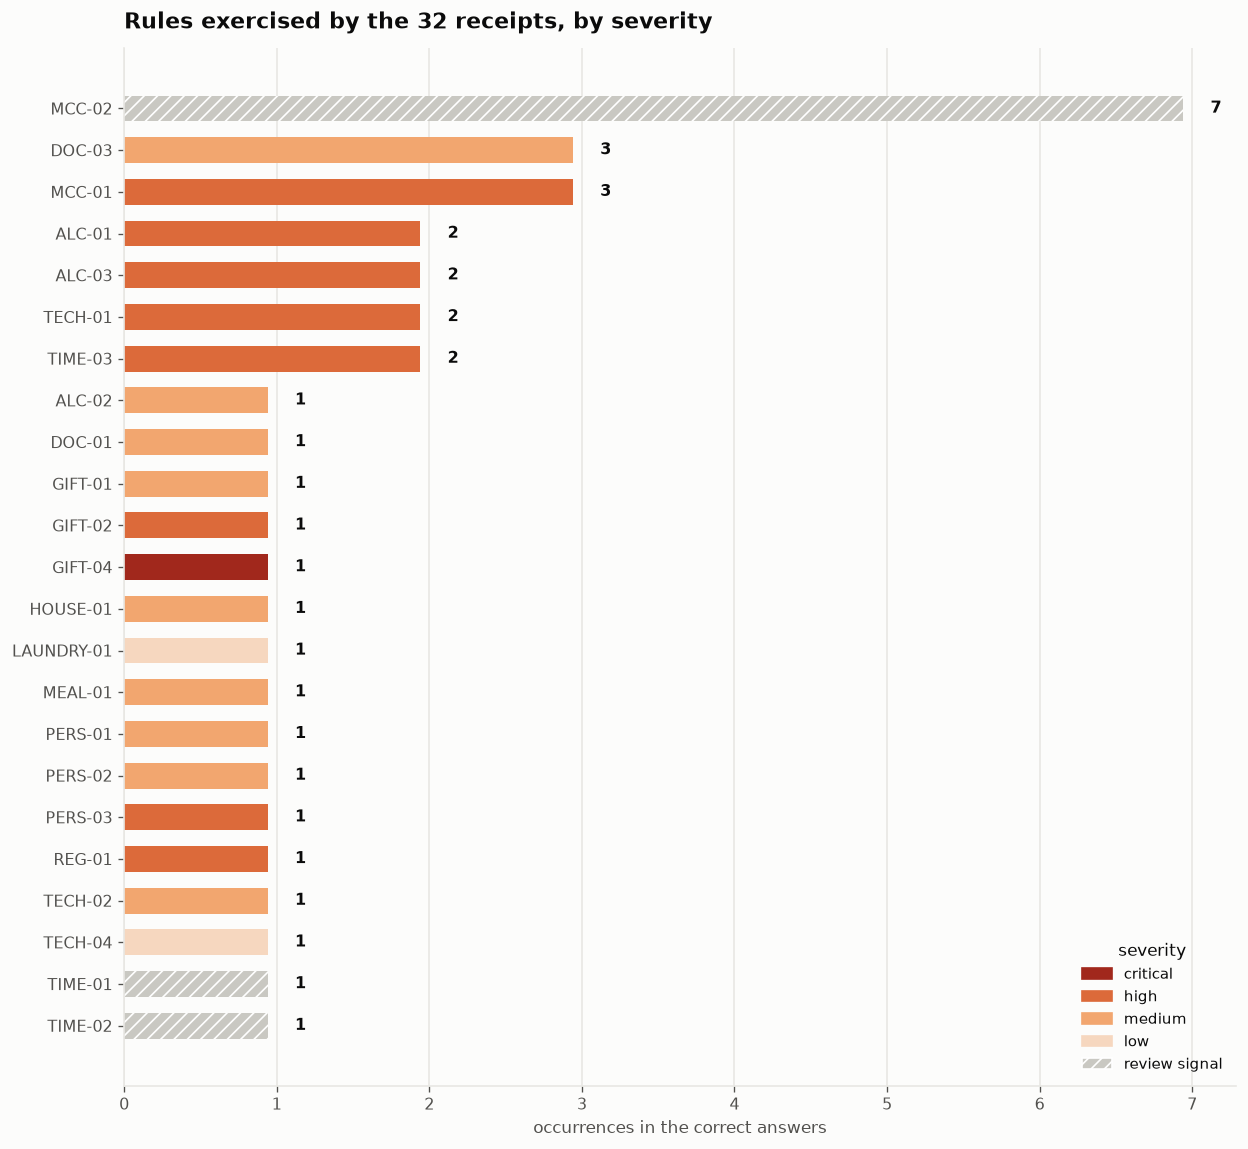

23 distinct rules appear; the engine has 37 checks of its own


In [6]:
sev_order = ["critical", "high", "medium", "low"]; sev_col = {"critical": "#a1281c", "high": "#dc6a3a", "medium": "#f2a66f", "low": "#f6d7bf"}
rule_sev = collections.defaultdict(collections.Counter)
for a in ANS.values():
    for r_, sv in a["exceptions"]: rule_sev[r_][sv] += 1
    for r_ in a["signals"]: rule_sev[r_]["signal"] += 1
rules_sorted = sorted(rule_sev, key=lambda r_: (-sum(rule_sev[r_].values()), r_))
fig, ax = plt.subplots(figsize=(10.5, 0.36 * len(rules_sorted) + 1.4)); y = np.arange(len(rules_sorted))[::-1]
for yi, r_ in zip(y, rules_sorted):
    left = 0
    for sv in sev_order + ["signal"]:
        n = rule_sev[r_].get(sv, 0)
        if n: ax.barh(yi, n - .06, left=left, height=.62, color=sev_col.get(sv, "#c9c8c2"), hatch="///" if sv == "signal" else None, edgecolor="white" if sv == "signal" else "none", linewidth=0); left += n
    ax.text(left + .12, yi, str(left), va="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(rules_sorted, fontsize=9.5); ax.set_xlabel("occurrences in the correct answers"); ax.grid(False); ax.xaxis.grid(True); ax.set_title("Rules exercised by the 32 receipts, by severity")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=sev_col[k], label=k) for k in sev_order] + [Patch(facecolor="#c9c8c2", hatch="///", edgecolor="white", label="review signal")], loc="lower right", title="severity", fontsize=9)
plt.tight_layout(); plt.show()
print(f"{len(rules_sorted)} distinct rules appear; the engine has {len(ea.EXPECTED)} checks of its own")

### 1.3 What the receipts look like
Declared expense type, entity (it decides which regional rules apply) and the language of each line description.

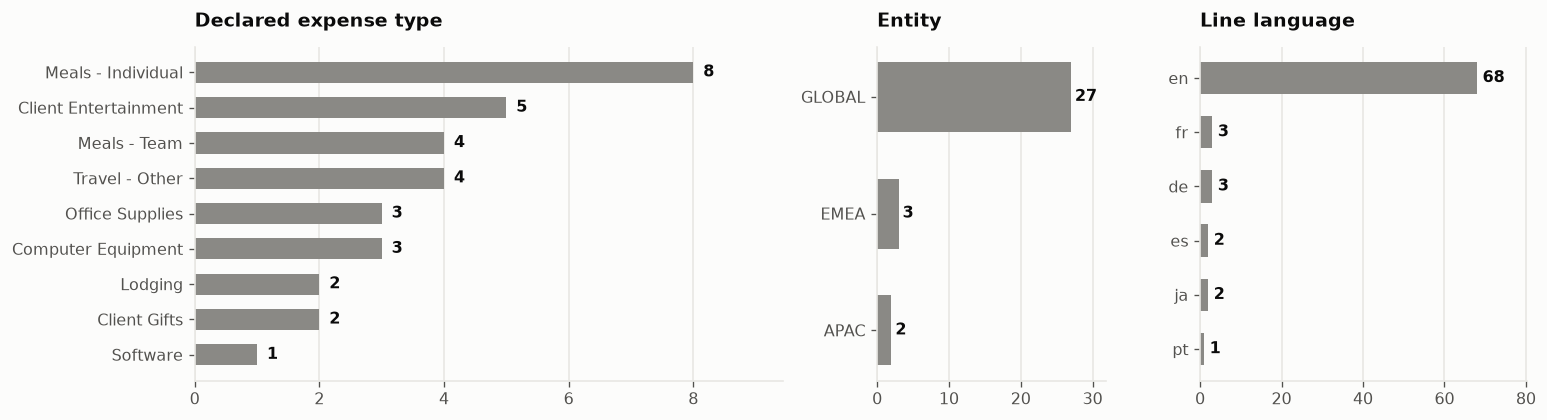

In [7]:
types = collections.Counter(a["type"] for a in ANS.values()); ents = collections.Counter(a["entity"] for a in ANS.values()); langs = collections.Counter(l["language"] for a in ANS.values() for l in a["lines"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.8, .7, 1]})
for a_, c_, t_ in [(ax[0], types, "Declared expense type"), (ax[1], ents, "Entity"), (ax[2], langs, "Line language")]:
    items = c_.most_common(); lab = [k for k, _ in items][::-1]; val = [v for _, v in items][::-1]
    bars = a_.barh(lab, val, height=.6, color=PAL["muted"]); a_.set_title(t_, fontsize=11.5); a_.grid(False); a_.xaxis.grid(True)
    for yy, v in enumerate(val): a_.text(v + max(val) * .02, yy, str(v), va="center", fontsize=9.5, fontweight="bold")
    a_.set_xlim(0, max(val) * 1.18)
plt.tight_layout(); plt.show()

### 1.4 The 21 categories: what the classifier has to get right
Each line item must be placed in one category. Some categories are **restricted** (alcohol, tobacco, gambling, gift cards…): a line in one of them triggers rules by itself, so a wrong category changes the verdict.

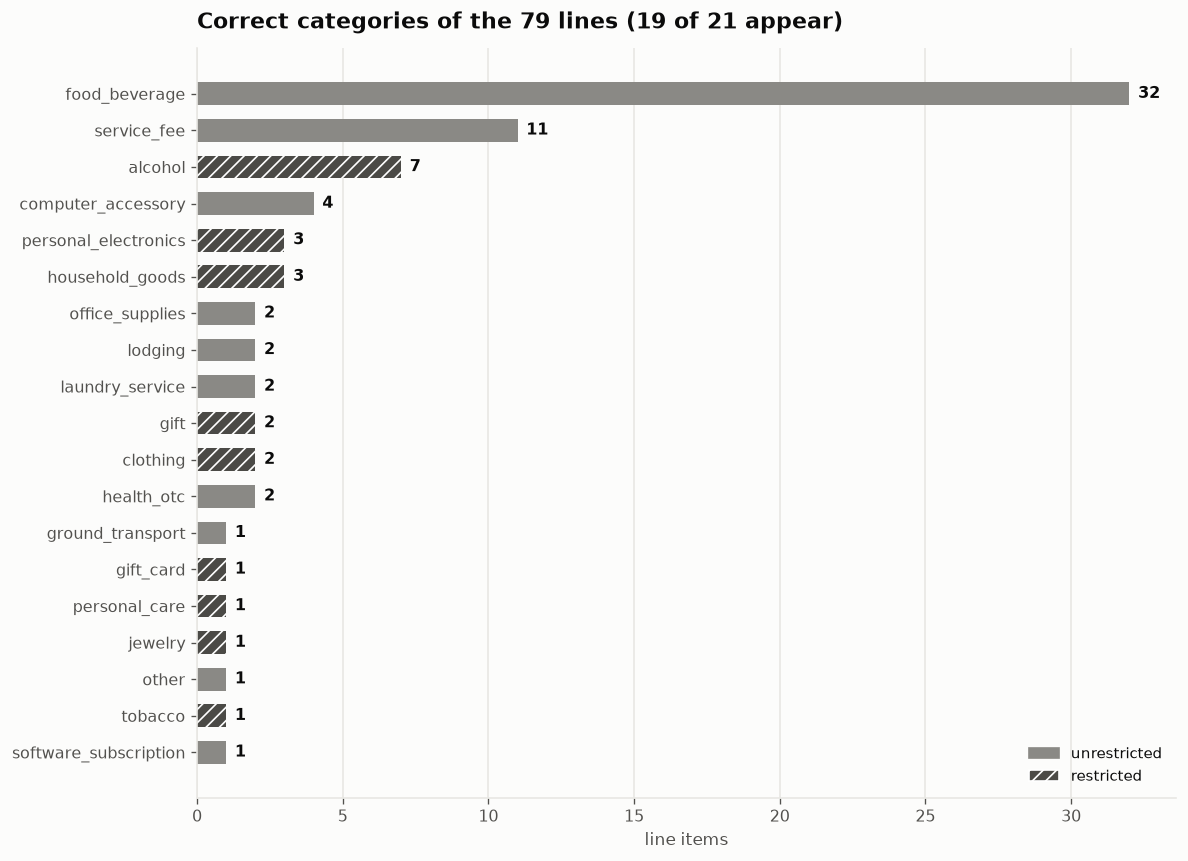

In [8]:
catc = collections.Counter((l["category"], l["restricted"]) for a in ANS.values() for l in a["lines"])
items = sorted(catc.items(), key=lambda kv: -kv[1])
fig, ax = plt.subplots(figsize=(10, 0.32 * len(items) + 1.2)); y = np.arange(len(items))[::-1]
for yi, ((cat, restr), n) in zip(y, items):
    ax.barh(yi, n, height=.62, color="#4b4a46" if restr else PAL["muted"], hatch="///" if restr else None, edgecolor="white", linewidth=0); ax.text(n + .3, yi, str(n), va="center", fontsize=9.5, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([c for (c, _), _ in items], fontsize=9.5); ax.grid(False); ax.xaxis.grid(True); ax.set_xlabel("line items"); ax.set_title(f"Correct categories of the {n_lines} lines ({len(items)} of 21 appear)")
ax.legend(handles=[Patch(color=PAL["muted"], label="unrestricted"), Patch(facecolor="#4b4a46", hatch="///", edgecolor="white", label="restricted")], loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

### 1.5 All 32 receipts with their correct answer
The trap column is the first sentence of Oversight's own `notes` field.

In [9]:
rows = [{"receipt": k, "type": a["type"], "correct answer": a["disposition"], "scored": "yes" if a["in_scope"] else "out of scope", "rules it should raise": "; ".join([p_ for p_ in [", ".join(f"{r_} ({sv})" for r_, sv in a["exceptions"]), ("signals: " + ", ".join(a["signals"])) if a["signals"] else ""] if p_]) or "-", "the trap": a["trap"]} for k, a in ANS.items()]
tab = pd.DataFrame(rows); tab = tab.apply(lambda c_: c_.str.replace("$", "&#36;", regex=False))
display(tab.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"}).map(dz.status_style, subset=["correct answer"]))

receipt,type,correct answer,scored,rules it should raise,the trap
RCP-001,Meals - Individual,pass,yes,-,Baseline clean receipt.
RCP-002,Client Entertainment,pass,yes,-,False-positive trap.
RCP-003,Office Supplies,pass,yes,-,Clean.
RCP-004,Meals - Team,pass,yes,-,"Keyword trap, four ways."
RCP-005,Lodging,pass,yes,-,Large total but entirely compliant.
RCP-006,Computer Equipment,pass,yes,-,"Threshold near-miss: $189 against the TECH-02 $200 per-item ceiling, so no pre-approval is required."
RCP-007,Meals - Team,pass,yes,-,Cap near-miss: $53.00 per person against the $75 cap.
RCP-008,Meals - Team,pass,yes,-,Multilingual clean receipt.
RCP-009,Travel - Other,pass,yes,-,LAUNDRY-01 near-miss in the compliant direction: a 5-night trip clears the 4-night minimum.
RCP-010,Meals - Individual,flag,yes,ALC-01 (high),The canonical alcohol violation.


In [10]:
dz.banner(2, 'The architecture, and does the engine agree with the answer key?', 'The two lines of defense, and whether the engine reproduces the answer key')

We built **two lines of defense** around one rule: *the deterministic engine decides; the LLMs only help.*

- **First line, the original task:** per receipt: normalizer → classifier (an LLM puts one category on each line) → retriever → 37 checks in plain code → verdict. The disposition is **computed** (EXC-01): a medium, high or critical exception → `flag`; only low exceptions or signals → `review`; nothing → `pass`.
- **Second line, new in this project:** the engine cannot see patterns across receipts (next section). A bounded LLM reads each employee's month, with summaries computed by code, and can only **escalate** a `pass` to `review`. It never lowers a flag.
- **Offline:** how the second line is built (fraud schemes verified by the engine), fine-tuned, evaluated and gated before it is allowed to ship.

Notebook `02_deterministic_engine` shows the 41 rules, thresholds and boundary tests of the first line.

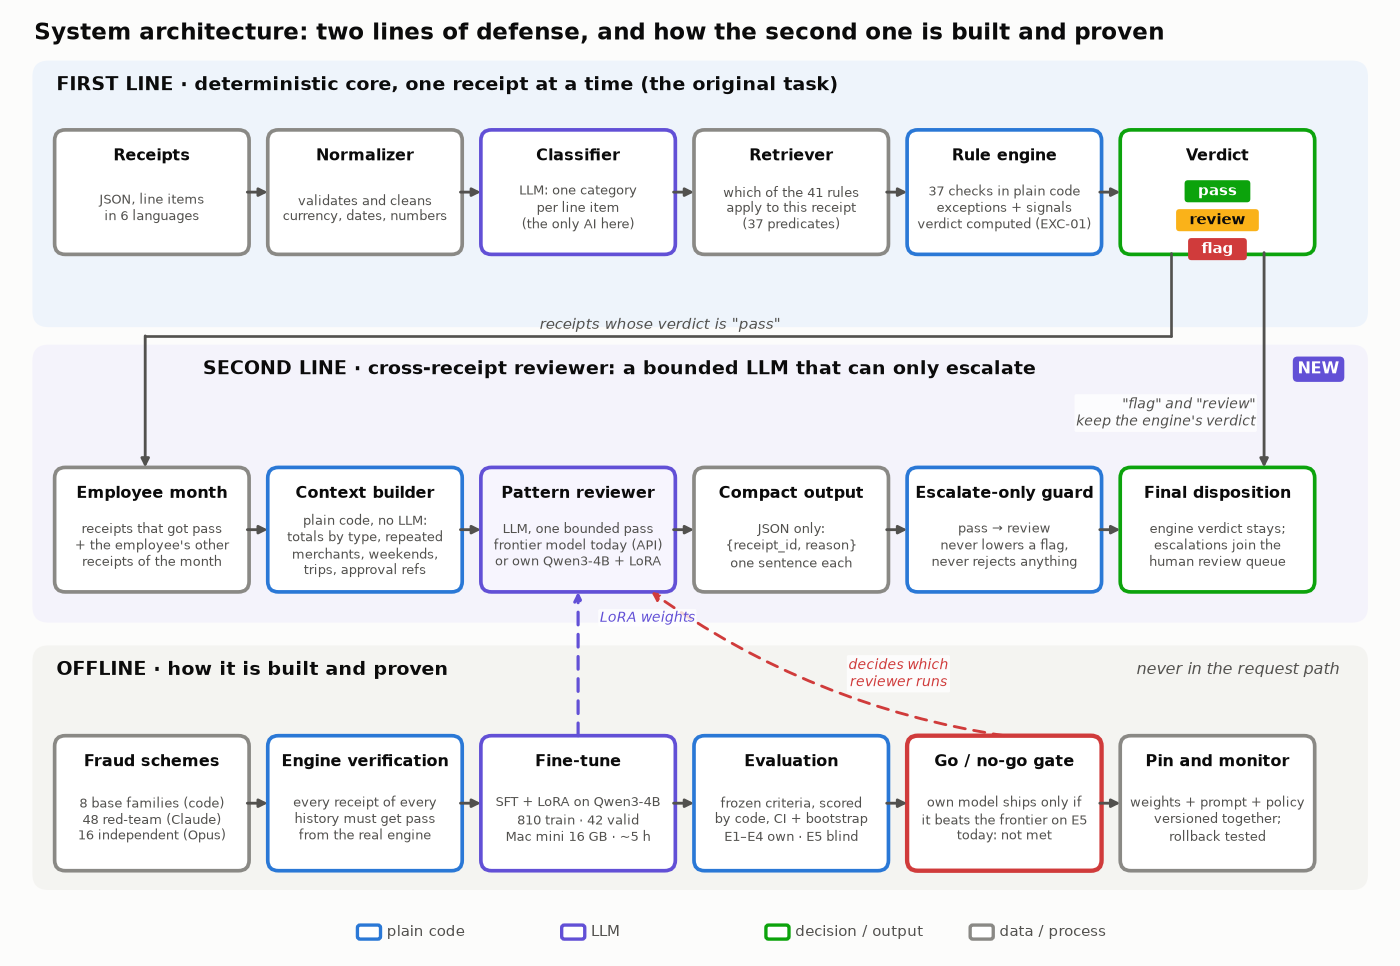

In [11]:
dz.architecture_diagram()

### Does the first line reproduce the answer key?
We run **only the engine** (code, no network) on the 32 receipts with the categories the classifier produced, and compare with Oversight's correct answers from section 1. One input needs outside help: `RCP-022-L2` is a gift to a public official, a fact the classifier delivers as a *recipient* (`gift_for`); the saved report does not store it, so we set it by hand.

In [12]:
cats, uncertain = {}, {}
rep = {r["receipt_id"]: r for r in map(json.loads, open(ENG/"report.jsonl"))}
for rid, r in rep.items():
    for l in r["line_items"]:
        cats[l["line_id"]] = l["category"]
        if l["confidence_band"] == "low": uncertain.setdefault(rid, set()).add(l["line_id"])
res32 = ea.evaluate_receipts(R, cats, {"RCP-022-L2": ("government_official", "R. Delgado")}, uncertain)
cnt = ea.summary(res32)
print('matches the pipeline saved report:', sum(res32[k].disposition == rep[k]['disposition'] for k in rep), '/ 32')

matches the pipeline saved report: 32 / 32


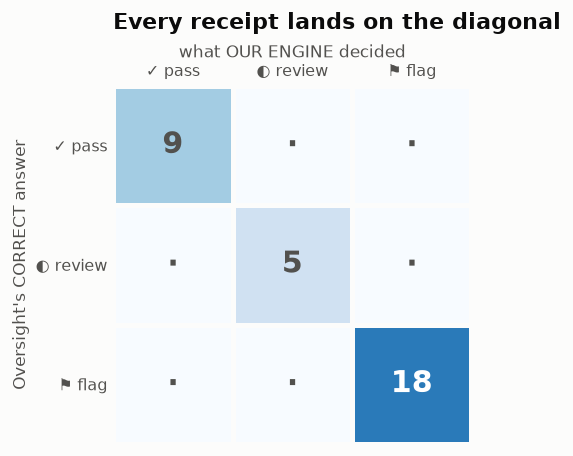

In [13]:
lab = {k: a["disposition"] for k, a in ANS.items()}; labels3 = ["pass", "review", "flag"]; M3 = np.zeros((3, 3), int)
for k in lab: M3[labels3.index(lab[k]), labels3.index(res32[k].disposition)] += 1
agree = sum(res32[k].disposition == lab[k] for k in lab); agree_scored = sum(res32[k].disposition == lab[k] for k in scored)
gold_cat = {l["id"]: l["category"] for a in ANS.values() for l in a["lines"]}; cat_ok = sum(cats[l] == gold_cat[l] for l in gold_cat)
exp_sets = {k: {r_ for r_, _ in a["exceptions"]} | set(a["signals"]) for k, a in ANS.items()}; rule_ok = sum({r_ for r_, _, _ in res32[k].fired} == exp_sets[k] for k in ANS)
dz.kpis([(f"{agree}/32", "dispositions match", f"{agree_scored}/{len(scored)} on the 28 scored receipts", PAL["good"]), (f"{cat_ok}/{len(gold_cat)}", "line categories match", "classifier vs the answer key", PAL["good"]),
         (f"{rule_ok}/32", "exact rule sets match", "same rules fired as expected", PAL["good"]), ("in-sample", "read with care", "also our development set", PAL["warn"])])
fig, ax = plt.subplots(figsize=(4.6, 3.9)); ax.imshow(M3, cmap="Blues", vmin=0, vmax=M3.max() * 1.4); icons = ["✓ pass", "◐ review", "⚑ flag"]
for i_ in range(3):
    for j_ in range(3): ax.text(j_, i_, str(M3[i_, j_]) if M3[i_, j_] else "·", ha="center", va="center", fontsize=18, fontweight="bold", color="white" if M3[i_, j_] > M3.max() * .55 else PAL["ink2"])
ax.set_xticks(range(3)); ax.set_xticklabels(icons); ax.set_yticks(range(3)); ax.set_yticklabels(icons); ax.xaxis.tick_top(); ax.xaxis.set_label_position("top")
ax.set_xlabel("what OUR ENGINE decided"); ax.set_ylabel("Oversight's CORRECT answer"); ax.grid(False); [s_.set_visible(False) for s_ in ax.spines.values()]
ax.set_xticks(np.arange(-.5, 3), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True); ax.grid(which="minor", color=PAL["surface"], lw=3); ax.tick_params(which="both", length=0)
ax.set_title("Every receipt lands on the diagonal", pad=34); plt.tight_layout(); plt.show()

In [14]:
dz.callout('warn', 'A perfect score here is a <b>reproducibility check, not a generalization claim</b>: the validator was developed and measured on these same 32 receipts. How well the classifier generalizes was measured separately (Annex 3): on a 144-line hand-written held-out set Haiku got 137 to 139 correct, and on a 417-line synthetic benchmark Haiku reached 98.3% and Sonnet 98.8%.', 'Read it with care')

In [15]:
dz.callout('learned', 'The engine solves the task as posed, is auditable (each verdict cites the rule and the numbers) and reproducible (32/32). It is the core and stays untouched.')

In [16]:
dz.banner(3, "The engine's limit: it does not see patterns across receipts", 'What can the engine NOT see?')

Almost all rules look at **one receipt at a time**. An employee who splits, repeats or mixes expenses across several receipts, **each within the limit**, triggers nothing. Minimal example, with the real engine:

In [17]:
c = ea.create_receipt
def gift(i, day, amount):
    r, k = c(f"G{i}", "Client Gifts", "Southern Flowers", "5992", f"2026-05-{day:02d}T11:00:00", [("Flower arrangement", "gift", amount, 1)])
    return r, k, {r["line_items"][0]["line_id"]: ("client", "Ana Pérez")}
cases = [(f"gift {i+1}: ${m} to Ana Pérez on May {d}", *gift(i + 1, d, m)) for i, (d, m) in enumerate([(5, 49.0), (12, 48.5), (19, 49.5), (26, 47.0)])]
display(pd.DataFrame(ea.probe(cases), columns=["receipt", "engine", "rules"]).style.hide(axis="index"))
print(f"Total to the same person in the month: ${49 + 48.5 + 49.5 + 47:.2f}   (the cap is $50 per gift, and every gift is below it)")

receipt,engine,rules
gift 1: $49.0 to Ana Pérez on May 5,pass,-
gift 2: $48.5 to Ana Pérez on May 12,pass,-
gift 3: $49.5 to Ana Pérez on May 19,pass,-
gift 4: $47.0 to Ana Pérez on May 26,pass,-


Total to the same person in the month: $194.00   (the cap is $50 per gift, and every gift is below it)


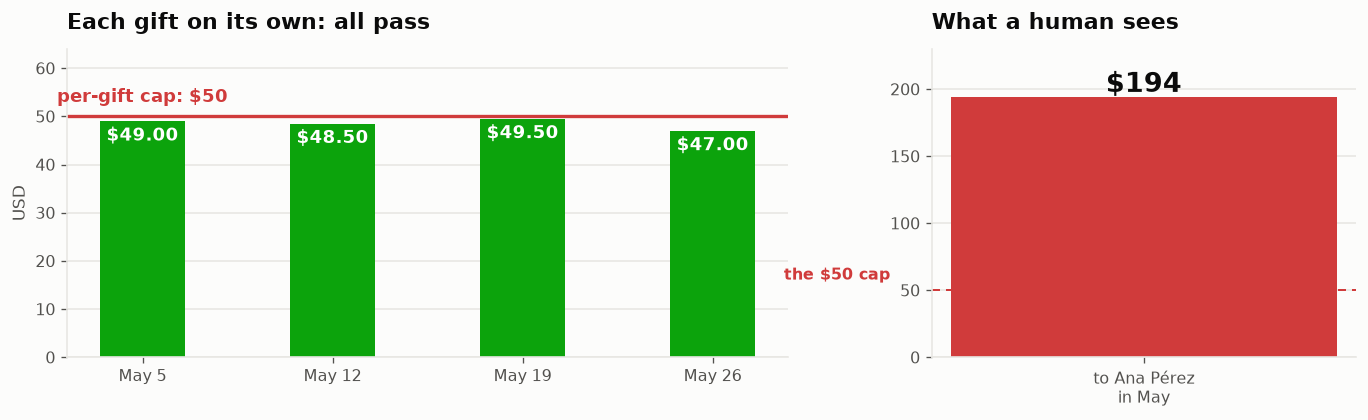

In [18]:
gifts = [49.0, 48.5, 49.5, 47.0]; dates = ["May 5", "May 12", "May 19", "May 26"]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
b = ax[0].bar(dates, gifts, color=PAL["good"], width=.45); ax[0].axhline(50, color=PAL["crit"], lw=2); ax[0].text(-.45, 53, "per-gift cap: $50", ha="left", color=PAL["crit"], fontsize=10.5, fontweight="bold")
[ax[0].text(r.get_x() + r.get_width() / 2, r.get_height() - 4, f"${r.get_height():.2f}", ha="center", color="white", fontsize=11, fontweight="bold") for r in b]; ax[0].set_ylim(0, 64); ax[0].set_ylabel("USD"); ax[0].set_title("Each gift on its own: all pass"); ax[0].grid(False); ax[0].yaxis.grid(True)
t = ax[1].bar(["to Ana Pérez\nin May"], [sum(gifts)], color=PAL["crit"], width=.45); ax[1].axhline(50, color=PAL["crit"], lw=1.2, ls=(0, (4, 3)))
ax[1].text(0, sum(gifts) + 4, f"${sum(gifts):.0f}", ha="center", fontsize=16, fontweight="bold"); ax[1].text(-.42, 58, "the $50 cap", fontsize=9.5, color=PAL["crit"], fontweight="bold"); ax[1].set_ylim(0, 230)
ax[1].set_title("What a human sees"); ax[1].grid(False); ax[1].yaxis.grid(True)
plt.tight_layout(); plt.show()

Four gifts of ~<span class="tex2jax_ignore">&#36;</span>49 to the same person add up to **<span class="tex2jax_ignore">&#36;</span>194** and the engine lets them through. A human auditor would see it in seconds. That is the **opportunity**: a reviewer that reads the employee's history and can **raise** a `pass` to `review`.

### The main argument (industry case study, Part 1)
> **"We wanted a way to review recent behavior without engineering a new feature for every pattern.** An LLM can compare the current transaction with the supplied history and apply fraud-review guidance expressed in natural language. Updating that guidance does not require retraining the model, although every change still needs validation against transaction outcomes."

**Our design, the same as theirs:** the LLM runs **after** the engine, **only escalates** (`pass → review`), **never lowers** a flag, and the verdict still belongs to the engine. The summaries (totals, repeated merchants, weekends) are computed by **code**, not by the LLM; the LLM only reads and points at receipts with a one-sentence reason.

In [19]:
dz.banner(4, 'How do we generate fraud schemes that the engine lets through?', 'Three sources of fraud patterns, from least to most independent')

There is no real data of this kind of fraud, so we **fabricate** it and **verify it with the real engine**. Three sources, from least to most independent:

1. **8 base families (code):** I defined them with real thresholds (gift under <span class="tex2jax_ignore">&#36;</span>50, equipment under <span class="tex2jax_ignore">&#36;</span>200, meals under <span class="tex2jax_ignore">&#36;</span>150…). The code builds the receipts and the engine verifies.
2. **Red team (48 schemes, 2 rounds):** Claude agents "play the cheating employee" and invent schemes I had not thought of. Every receipt must pass the engine; if the engine flags it, it is discarded.
3. **Independent E5 (16 schemes):** **Opus** agents, blind (without seeing our schemes, code or results), each wrote a new scheme **by hand** with fraud histories and clean months. **No model was trained on this**: it is the final test.

**Golden rule:** a history only counts if **all** of its receipts get `pass` from the engine. Live check with the `evaluate_history` function:

In [20]:
import glob
H = []
for f in sorted(glob.glob(str(DATA/"pattern_sources"/"*.json"))): H += json.load(open(f))
for f in sorted(glob.glob(str(DATA/"pattern_sources"/"*.jsonl"))): H += [json.loads(l) for l in open(f)]
res = collections.Counter(); bad = []
for h in H:
    out = ea.evaluate_history(h); ok = all(x.disposition == "pass" for x in out.values())
    res["pass" if ok else "fails"] += 1
    if not ok: bad.append(h["scheme"])
fr = sum(h["scheme"] != "clean" for h in H)
print(f"{len(H)} histories ({fr} with fraud, {len(H) - fr} clean) checked with the real engine: {dict(res)}")

496 histories (432 with fraud, 64 clean) checked with the real engine: {'pass': 496}


In [21]:
dz.callout('learned', "There is a broad family of pattern frauds that the engine cannot catch by construction. In an earlier test, a set of hand-written rules for 8 families detected 0% of the red team's new schemes: every new pattern would need its own rule, exactly the cost the industry case study wanted to avoid with an LLM.")

In [22]:
dz.banner(5, 'Catalog of the 72 patterns', 'Every pattern, in plain language')

Each row is a pattern: what the employee does, why the engine does not see it and what gives it away. The **role** column matters for evaluating properly: *Training* (the model saw them), *E1/E2* (held out: it did not see them), *E3* (seen families), *E5* (independent, never trained on).

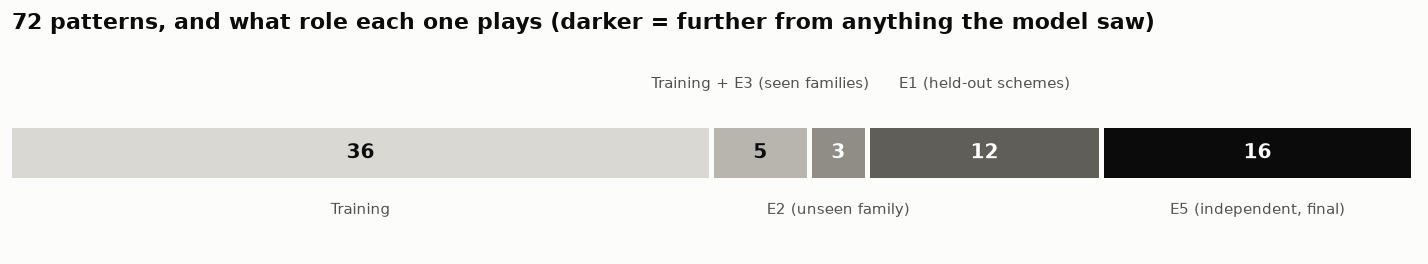

In [23]:
CATR = json.load(open(DATA/"catalog_patterns.json")); roles = [("Training", "Training"), ("Training and E3 test (seen)", "Training + E3 (seen families)"), ("E2 test (unseen family)", "E2 (unseen family)"), ("E1 test (held-out scheme)", "E1 (held-out schemes)"), ("Final E5 test (never trained on)", "E5 (independent, final)")]
cnts = collections.Counter(c["role"] for c in CATR); shades = ["#d9d8d3", "#b7b5ae", "#8f8d86", "#5f5e59", "#0b0b0b"]
fig, ax = plt.subplots(figsize=(12, 2.3)); left = 0
for (k, lab), col in zip(roles, shades):
    n = cnts[k]; ax.barh(0, n - .25, left=left, color=col, height=.5); ax.text(left + (n - .25) / 2, 0, str(n), ha="center", va="center", color="white" if col in ("#5f5e59", "#0b0b0b", "#8f8d86") else PAL["ink"], fontsize=12, fontweight="bold"); up = k in ("Training and E3 test (seen)", "E1 test (held-out scheme)"); ax.text(left + (n - .25) / 2, .62 if up else -.5, lab, ha="center", va="bottom" if up else "top", fontsize=9, color=PAL["ink2"]); left += n
ax.set_xlim(0, left); ax.set_ylim(-1.0, 1.05); ax.axis("off"); ax.set_title(f"{left} patterns, and what role each one plays (darker = further from anything the model saw)"); plt.tight_layout(); plt.show()

In [24]:
CAT = json.load(open(DATA/"catalog_patterns.json")); EN = {x["scheme"]: x for x in json.load(open(DATA/"catalog_en.json"))}
rows = []
for cc in CAT:
    e = EN.get(cc["scheme"], {})
    rows.append({"origin": cc["origin"].split(" (")[0], "role": cc["role"], "pattern": e.get("readable_name", cc["scheme"]), "what the employee does": e.get("what_it_does", cc["reason"]), "what gives it away": e.get("what_gives_it_away", ""), "id": cc["scheme"]})
df = pd.DataFrame(rows)
color = {"Training": "#e8eef7", "Training and E3 test (seen)": "#dff3e6", "E2 test (unseen family)": "#fff3c4", "E1 test (held-out scheme)": "#fde2c4", "Final E5 test (never trained on)": "#f9d3d3"}
display(HTML("<p><b>Total:</b> " + ", ".join(f"{k}: {v}" for k, v in df["role"].value_counts().items()) + f" = {len(df)} patterns; all of them pass the engine receipt by receipt.</p>"))
display(df.drop(columns=["id"]).style.apply(lambda r: [f"background-color:{color.get(r['role'], 'white')}"] * len(r), axis=1).set_properties(**{"white-space": "normal", "text-align": "left", "vertical-align": "top"}).hide(axis="index"))

origin,role,pattern,what the employee does,what gives it away
Base family,Training and E3 test (seen),Gifts Split Below Limit,"Buys several gifts for the same named client on different days, each just under the $50 per-receipt cap.","The same client's name keeps appearing, and the gifts together far exceed the cap."
Base family,Training and E3 test (seen),Unnamed Gifts Under Threshold,"Files many gifts without naming a recipient, each priced just under $10.","A pile of small, anonymous gifts that all sit just below the naming threshold."
Base family,Training and E3 test (seen),Equipment Priced Below Approval,"Repeatedly buys equipment priced just under $200, the per-item level that needs pre-approval.","Several similar gadgets, all priced just under the limit, bought close together."
Base family,Training and E3 test (seen),Unitemized Receipts Under Limit,"Submits repeated receipts with only a total, each just under $75, the amount above which an itemized list is required.",The same kind of vendor and the same near-limit totals keep recurring with no detail.
Base family,Training and E3 test (seen),Meals At The Daily Cap,Claims individual meals that repeatedly land at 96-99% of the per-person daily meal cap.,"Meal after meal lands almost exactly at the cap, which real eating rarely does."
Base family,E2 test (unseen family),Team Meals Below Documentation Line,"Files team meals repeatedly just under $150, the receipt total above which attendee details are needed.",Repeated team meals at the same place all sit just below the documentation threshold.
Base family,E2 test (unseen family),Same Expense Submitted Twice,Submits the same expense two times under different receipt ids to get paid twice.,"Two claims show the same merchant, date, amount and items."
Base family,E2 test (unseen family),One Approval Used Repeatedly,Reuses a single pre-approval reference to cover several separate large purchases.,The same approval reference is attached to several different purchases.
Red team round 1,Training,"Weekend Client Dinners, No Trip","Repeatedly claims client entertainment on Saturdays and Sundays when there is no trip or client visit, likely personal outings.",The claims cluster on weekends with no trip or client visit behind them.
Red team round 1,Training,Two Hotels Same Night,Claims two different hotels for the same night or nights within one trip.,"Two hotels are billed for the same night, so one is a double claim or a personal stay."


### One history from the inside (what the reviewer sees; the ◄ rows are planted and the reviewer does **not** see that mark)
Edit `CHOSEN` with any `id` from the table.

In [25]:
CHOSEN = ["same_client_serial_occasions", "meals_only_phantom_trip"]
for E in CHOSEN:
    cc = next(x for x in CAT if x["scheme"] == E); e = EN.get(E, {})
    display(HTML(f"<h4>{e.get('readable_name', E)} <small>({E}) · {cc['role']}</small></h4><p><b>What it does:</b> {e.get('what_it_does','')}<br><b>Why it passes the engine:</b> {e.get('why_it_passes','')}<br><b>What gives it away:</b> {e.get('what_gives_it_away','')}</p>"))
    print(cc["example_history"]); print()

EMPLOYEE HISTORY EJ (entity GLOBAL, all amounts in USD). Every receipt below was ALREADY checked by the deterministic engine and got verdict `pass`.

RECEIPTS (chronological):
- EJ-R01 | 2026-05-05 10:20 (Tue) | Petal & Stem Florists | Client Gifts | $46.00 | Congratulations bouquet for Daniel Whitford - new office   ◄ PLANTED
- EJ-R02 | 2026-05-06 12:40 (Wed) | Harbor Lane Bistro | Meals - Team | $51.50, 3 attendees | Grilled chicken sandwich (x2) + Caesar salad + Iced tea (x3)
- EJ-R03 | 2026-05-07 15:05 (Thu) | Clearline Stationers | Office Supplies | $28.98 | Spiral notebooks, 5-pack + Gel pens, black, 12 ct + Sticky notes 3x3 (x2)
- EJ-R04 | 2026-05-12 16:30 (Tue) | Chapter House Books | Client Gifts | $44.00 | Hardcover leadership book, gift-wrapped, for Daniel Whitford - thank-you   ◄ PLANTED
- EJ-R05 | 2026-05-13 09:45 (Wed) | Buckeye Cab Co | Travel - Other | $31.40, TRIP-5102 (2 nights) | Taxi airport to hotel
- EJ-R06 | 2026-05-14 19:30 (Thu) | Short North Grill | Meals - In

EMPLOYEE HISTORY EJ (entity GLOBAL, all amounts in USD). Every receipt below was ALREADY checked by the deterministic engine and got verdict `pass`.

RECEIPTS (chronological):
- EJ-R01 | 2026-05-04 10:15 (Mon) | LoopLine Stationers | Office Supplies | $29.48 | Copy paper, letter, 500 sh (x2) + Gel pens, black, 12-pack
- EJ-R02 | 2026-05-06 12:30 (Wed) | Monroe Noodle Bar | Meals - Team | $86.90, 4 attendees | Tonkotsu ramen bowl (x4) + Pork gyoza, 6 pc (x2) + Iced green tea (x4)
- EJ-R03 | 2026-05-12 12:40 (Tue) | Wabash Street Deli | Meals - Individual | $16.85, 1 attendees, TRIP-5307 (2 nights) | Turkey club on rye + Cup of tomato soup   ◄ PLANTED
- EJ-R04 | 2026-05-13 12:25 (Wed) | Monroe Noodle Bar | Meals - Individual | $19.40, 1 attendees, TRIP-5307 (2 nights) | Spicy miso ramen + Edamame, small   ◄ PLANTED
- EJ-R05 | 2026-05-14 12:35 (Thu) | Wabash Street Deli | Meals - Individual | $19.50, 1 attendees, TRIP-5307 (2 nights) | Pastrami melt + Side pasta salad + Sparkling water   

In [26]:
dz.banner(6, 'Training and evaluation data, and how we avoid cheating ourselves', 'What do we train and test on, and how do we avoid fooling ourselves?')

**Two AI tasks, two datasets** (the classifier details are in the annex `ANNEX_2_synthetic_dataset_classifier`):

| Task | What is generated | Size | How the label is guaranteed |
|---|---|---|---|
| **Classify lines** (which category?) | receipts with lines in 6 languages | 772 receipts / 2,651 training lines; benchmark of 122 receipts / 417 lines | **code decides** the label; Sonnet only writes text; blind audit with Haiku: 95.2% exact |
| **Review patterns** (is there fraud across receipts?) | one-month histories per employee | 810 training + 42 validation; 275 evaluation (E1–E4); 160 independent (E5) | patterns are **planted** and the **real engine verifies** that all of them pass |

**Anti-cheating (what we did so the evaluation is worth something):**
- The success criteria were written and **frozen before measuring** (`FINETUNE_LOG.md`, §9 and §13).
- The **evaluation schemes were held out by name** (12 schemes and 3 families the model did not see).
- **E5 was written blind by another model** and frozen with a hash before anything was run on it.
- **All candidates are compared with the same prompt, the same histories and the same deterministic score.**
- Metrics with confidence intervals (Wilson) and differences with paired *bootstrap*.

In [27]:
dz.banner(7, 'Why Qwen3-4B, and how do we train it?', 'Hardware limits, model choice and training recipe')

**Why a small model of our own:** the goal is a reviewer that runs **on the 16 GB Mac mini**, without sending receipts to a third party and with a fixed version. It is what the industry case study did (Qwen3.5-9B on a 96 GB GPU) adapted to what we have.

**Why Qwen3-4B-Instruct-2507 and not the Qwen3.5 we wanted** (measured, not assumed):

| Model (MLX, 16 GB) | Measured result |
|---|---|
| Qwen3.5-4B (all precisions) and 2B | run **out of memory** with sequences ≥ 768–1,536 tokens: our histories are ~1,400 tokens long |
| Qwen3.5 4-bit | only fits with 512-token sequences (~33 tok/s) |
| **Qwen3-4B-Instruct-2507, 4-bit** | **1,536 sequence length, 16 LoRA layers, 173 tok/s, 5.6 GB peak** ✓ |

*(Switching from Qwen3.5 to Qwen3 was approved by the user; see `FINETUNE_LOG.md`.)*

**Method:** SFT with **LoRA** (rank 16, scale 20, dropout 0.05, 16 layers, lr 1e-4, batch 4, 400 iterations, `--mask-prompt` so it only learns the answer, seed 11). The industry case study used RLVR (GRPO); it does not fit in 16 GB, so SFT is the documented fallback.

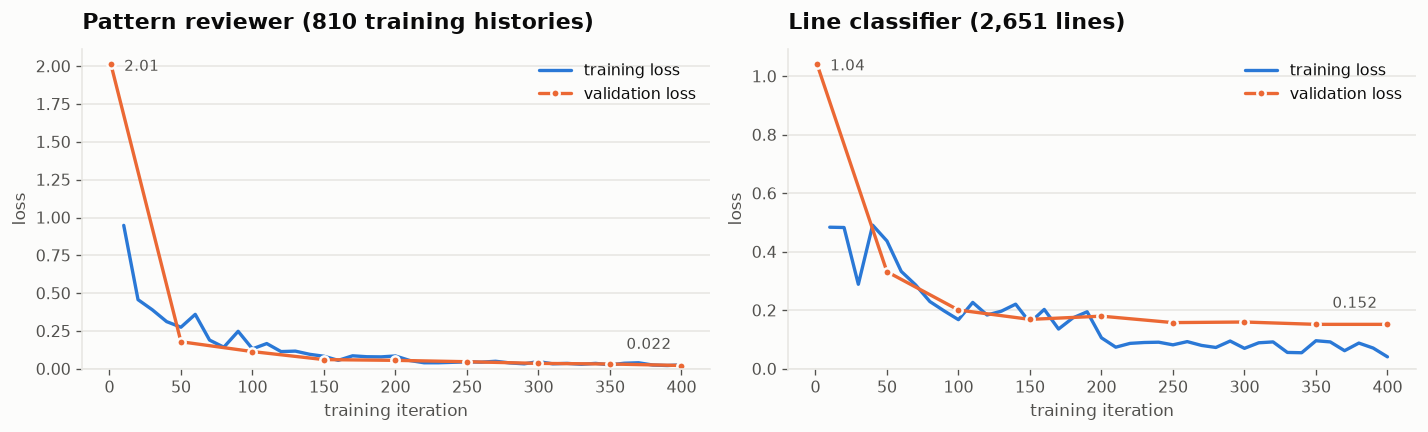

In [28]:
cv = json.load(open(DATA/"curve_reviewer.json")); cc_ = json.load(open(DATA/"curve_classifier.json"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.7))
for a, d, t in [(ax[0], cv, "Pattern reviewer (810 training histories)"), (ax[1], cc_, "Line classifier (2,651 lines)")]:
    tx, ty = [x[0] for x in d["train"]], [x[1] for x in d["train"]]; vx, vy = [x[0] for x in d["val"]], [x[1] for x in d["val"]]
    a.plot(tx, ty, color=PAL["ft"], label="training loss"); a.plot(vx, vy, color=PAL["sonnet"], marker="o", ms=5, mec=PAL["surface"], mew=1.5, label="validation loss")
    a.annotate(f"{vy[0]:.2f}", (vx[0], vy[0]), textcoords="offset points", xytext=(8, -4), color=PAL["ink2"], fontsize=9); a.annotate(f"{vy[-1]:.3f}", (vx[-1], vy[-1]), textcoords="offset points", xytext=(-6, 10), color=PAL["ink2"], fontsize=9, ha="right")
    a.set_title(t); a.set_xlabel("training iteration"); a.set_ylabel("loss"); a.legend(loc="upper right"); a.set_ylim(bottom=0)
plt.tight_layout(); plt.show()
dz.kpis([("400", "iterations", "LoRA rank 16, 16 layers", PAL["muted"]), ("~5 h", "reviewer training", "Mac mini, 16 GB", PAL["muted"]), ("5.6 GB", "peak memory", "4-bit Qwen3-4B", PAL["ft"]), (f"{cv['val'][-1][1]}", "final validation loss", "same generator as training!", PAL["warn"])])

**Honest reading of the curve:** the validation loss goes down cleanly, but **the validation set comes from the same generator as the training set**. A good curve only proves the model learned *that* data. What matters is what comes next: does it work on data our generator did not write?

In [29]:
dz.banner(8, 'Results against frontier models', 'Does our model beat the frontier models?')

### 8.1 How it is scored (reference style, Part 2): deterministic, no judges
- **Recall per history:** of the histories with fraud, in how many did the reviewer escalate ≥1 planted receipt?
- **False alarms:** of the **clean** histories, in how many did it escalate anything? (each one costs a human time)
- **Receipt precision / F1** and **dollar-weighted recall** (a <span class="tex2jax_ignore">&#36;</span>5,000 fraud weighs more than a <span class="tex2jax_ignore">&#36;</span>20 one).
The score is code (`evaluation.py`), not an LLM.

In [30]:
B = ev.load()
E14, E5 = B["E14"], B["E5"]
rows = []
for exam, kinds in [("E1 · held-out schemes", ["E1_heldout_schemes"]), ("E2 · unseen families", ["E2_unseen_families"]), ("E3 · seen families", ["E3_seen_families"])]:
    for model, pred in E14["pred"].items():
        m = ev.metrics(E14["key"], E14["amt"], pred, kinds, "E4_clean_control"); rows.append({"exam": exam, "model": model, "detected": f"{round(m['recall']*m['n_fraud'])}/{m['n_fraud']}", "recall": f"{100*m['recall']:.0f}%  CI{m['recall_ci']}"})
print("Clean controls (E4, 91 histories): fine-tuned ->", end=" "); m = ev.metrics(E14["key"], E14["amt"], E14["pred"]["Qwen3-4B fine-tuned"], ["E1_heldout_schemes"], "E4_clean_control"); print(f"{100*m['false_alarms']:.0f}% false alarms; Haiku (earlier run): 11% (10/91); Sonnet:", end=" ")
m = ev.metrics(E14["key"], E14["amt"], E14["pred"]["Sonnet 5.5 (agents)"], ["E1_heldout_schemes"], "E4_clean_control"); print(f"{100*m['false_alarms']:.0f}%")

Clean controls (E4, 91 histories): fine-tuned -> 0% false alarms; Haiku (earlier run): 11% (10/91); Sonnet: 10%


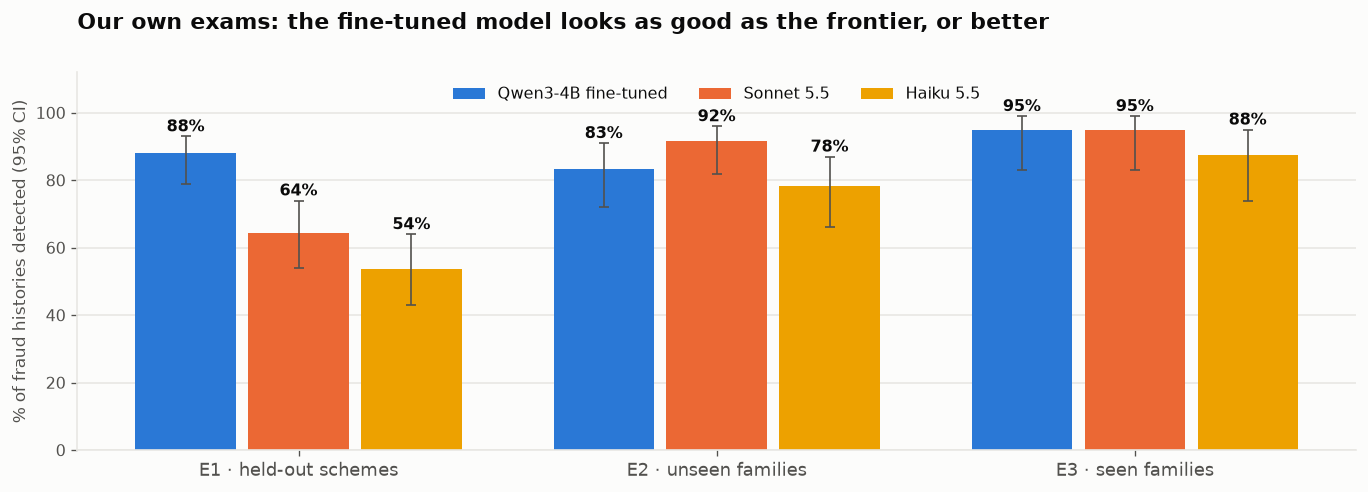

In [31]:
exams = ["E1 · held-out schemes", "E2 · unseen families", "E3 · seen families"]; models = [("Qwen3-4B fine-tuned", PAL["ft"]), ("Sonnet 5.5 (agents)", PAL["sonnet"]), ("Haiku 5.5 (agents)", PAL["haiku"])]
kinds = {"E1 · held-out schemes": ["E1_heldout_schemes"], "E2 · unseen families": ["E2_unseen_families"], "E3 · seen families": ["E3_seen_families"]}
fig, ax = plt.subplots(figsize=(11.5, 4.2)); w = .24
for j, (mname, col) in enumerate(models):
    vals, lo, hi = [], [], []
    for e in exams:
        m = ev.metrics(E14["key"], E14["amt"], E14["pred"][mname], kinds[e], "E4_clean_control"); v = 100 * m["recall"]; vals.append(v); lo.append(v - m["recall_ci"][0]); hi.append(m["recall_ci"][1] - v)
    xs = np.arange(len(exams)) + (j - 1) * (w + .03)
    bars = ax.bar(xs, vals, w, color=col, label=mname.replace(" (agents)", "")); ax.errorbar(xs, vals, yerr=[lo, hi], fmt="none", ecolor=PAL["ink2"], elinewidth=1, capsize=3)
    for x, v, h in zip(xs, vals, hi): ax.text(x, v + h + 1.5, f"{v:.0f}%", ha="center", fontsize=9.5, fontweight="bold")
ax.set_xticks(np.arange(len(exams))); ax.set_xticklabels(exams, fontsize=10.5); ax.set_ylim(0, 112); ax.set_ylabel("% of fraud histories detected (95% CI)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.0))
ax.set_title("Our own exams: the fine-tuned model looks as good as the frontier, or better", pad=26); plt.tight_layout(); plt.show()

### 8.2 First result (E1–E4): it looks like a victory
On **E1** (schemes the model did not see) the fine-tuned model detected **88%**, against 64% for Sonnet and 54% for Haiku, and had **0%** false alarms on the clean ones. On E2 (unseen families) Sonnet beat it (92% vs 83%) and on E3 (seen families) they tie (95%). With that result we would have said "we beat the frontier" on the hardest part.

**But those exams come from the same generator as the training** (same author, same style of receipts and clean months). That is why we built E5.

### 8.3 The independent test (E5): 96 fraud histories from 16 new schemes + 64 clean months, written by another model
All candidates with the **same prompt**, the **same 160 histories** and the **same score**:

In [32]:
rows = []
for model, pred in E5["pred"].items():
    m = ev.metrics(E5["key"], E5["amt"], pred, ["E5_independent"], "E5_clean")
    rows.append({"model": model, "history recall": m["recall"], "CI95": m["recall_ci"], "dollar recall": m["recall_usd"], "false alarms": m["false_alarms"], "FA CI95": m["fa_ci"], "receipt precision": m["receipt_precision"], "receipt F1": m["receipt_f1"], "escalates on fraud": m["escalates_on_fraud"], "escalates on clean": m["escalates_on_clean"]})
T5 = pd.DataFrame(rows).set_index("model")
fmt = {c: "{:.0%}" for c in ["history recall", "dollar recall", "false alarms", "receipt precision", "receipt F1", "escalates on fraud", "escalates on clean"]}

In [33]:
show = T5.sort_values("history recall", ascending=False).copy(); fa_num = show["false alarms"].tolist()
show["history recall (95% CI)"] = [f"{100*r:.0f}%  ({lo}–{hi})" for r, (lo, hi) in zip(show["history recall"], show["CI95"])]
show["false alarms (95% CI)"] = [f"{100*r:.0f}%  ({lo}–{hi})" for r, (lo, hi) in zip(show["false alarms"], show["FA CI95"])]
show = show[["history recall (95% CI)", "dollar recall", "false alarms (95% CI)", "receipt precision", "receipt F1", "escalates on fraud", "escalates on clean"]]
sty = show.style.format({c: "{:.0%}" for c in ["dollar recall", "receipt precision", "receipt F1", "escalates on fraud", "escalates on clean"]}).set_properties(**{"text-align": "center"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
sty = sty.apply(lambda col: [f"background-color: rgba(208,59,59,{min(.85, v):.2f}); color: {'white' if v > .5 else 'black'}" for v in fa_num], subset=["false alarms (95% CI)"])
display(sty)

,history recall (95% CI),dollar recall,false alarms (95% CI),receipt precision,receipt F1,escalates on fraud,escalates on clean
model,,,,,,,
Sonnet 5.5 agents + 4 examples,88% (79–93),79%,0% (0–6),100%,93%,88%,0%
"Sonnet 5.5 agents, run B",85% (77–91),74%,0% (0–6),100%,91%,85%,0%
Qwen3-4B fine-tuned,80% (71–87),81%,97% (89–99),45%,55%,91%,97%
"Sonnet 5.5 agents, run A",79% (70–86),64%,0% (0–6),100%,88%,79%,0%
"Sonnet 5.5 agents, run C",74% (64–82),64%,0% (0–6),100%,84%,74%,0%
Haiku 5.5 (agents),68% (58–76),55%,2% (0–8),99%,81%,68%,2%
Sonnet 5.5 API (1 call per history),49% (39–59),42%,5% (2–13),91%,63%,53%,5%
Opus 4.5 API,46% (36–56),47%,3% (1–11),93%,60%,49%,3%
Opus 4.5 API + 4 examples,36% (28–46),41%,0% (0–6),97%,53%,36%,0%


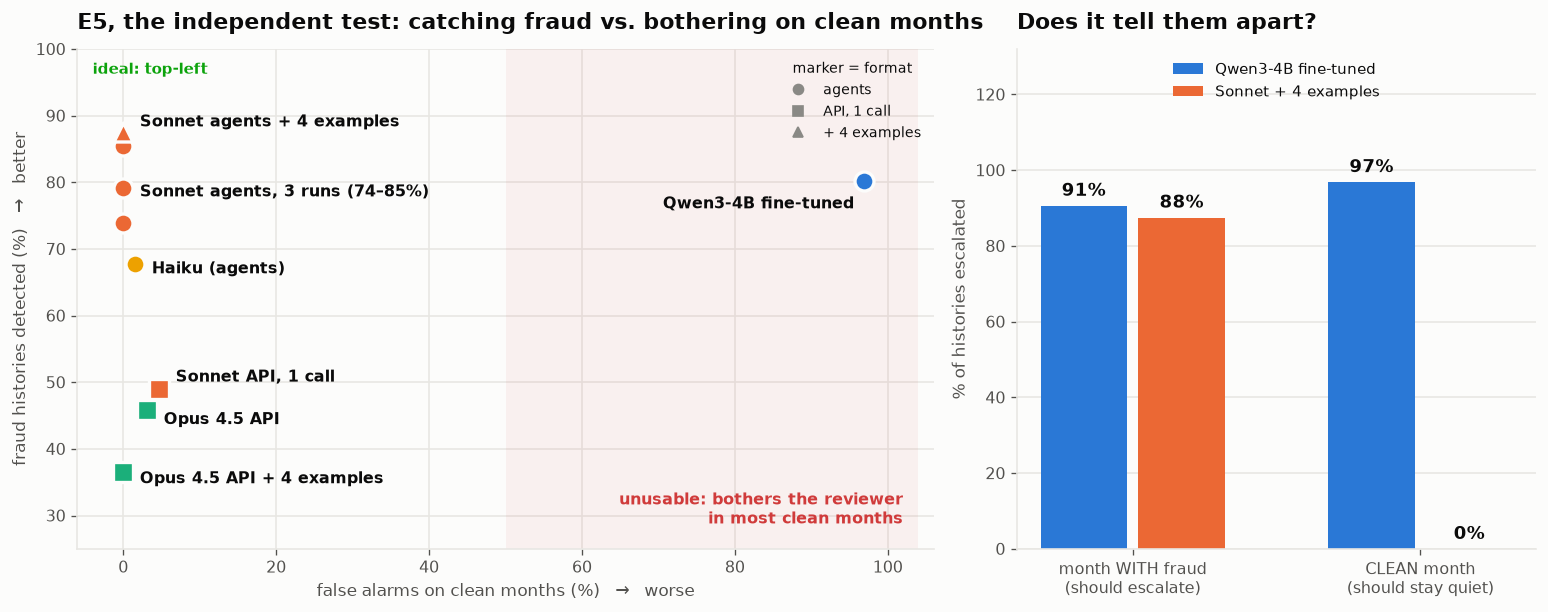

In [34]:
import matplotlib.patheffects as pe
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.65, 1]})
a = ax[0]; a.grid(True, axis="both"); a.axvspan(50, 104, color=PAL["crit"], alpha=.06, lw=0); a.text(102, 28, "unusable: bothers the reviewer\nin most clean months", ha="right", color=PAL["crit"], fontsize=9.5, fontweight="bold", va="bottom")
pts = {"Qwen3-4B fine-tuned": ("o", (-6, -14), "Qwen3-4B fine-tuned"), "Sonnet 5.5 agents, run A": ("o", (9, -3), None), "Sonnet 5.5 agents, run B": ("o", (9, -3), None), "Sonnet 5.5 agents, run C": ("o", (9, -3), None),
       "Sonnet 5.5 agents + 4 examples": ("^", (10, 6), "Sonnet agents + 4 examples"), "Haiku 5.5 (agents)": ("o", (10, -3), "Haiku (agents)"), "Sonnet 5.5 API (1 call per history)": ("s", (10, 7), "Sonnet API, 1 call"),
       "Opus 4.5 API": ("s", (10, -6), "Opus 4.5 API"), "Opus 4.5 API + 4 examples": ("s", (10, -4), "Opus 4.5 API + 4 examples")}
for name, (mk, off, lab) in pts.items():
    m = T5.loc[name]; x, y = 100 * m["false alarms"], 100 * m["history recall"]; a.scatter(x, y, s=130, marker=mk, color=dz.entity_color(name), edgecolor=PAL["surface"], linewidth=2, zorder=3)
    if lab: a.annotate(lab, (x, y), textcoords="offset points", xytext=off, fontsize=9.5, color=PAL["ink"], fontweight="bold", ha="right" if x > 60 else "left", va="center")
a.annotate("Sonnet agents, 3 runs (74–85%)", (0, 79), textcoords="offset points", xytext=(10, -2), fontsize=9.5, color=PAL["ink"], fontweight="bold", va="center")
a.set_xlim(-6, 106); a.set_ylim(25, 100); a.set_xlabel("false alarms on clean months (%)   →   worse"); a.set_ylabel("fraud histories detected (%)   →   better")
a.set_title("E5, the independent test: catching fraud vs. bothering on clean months"); a.text(-4, 98, "ideal: top-left", fontsize=9, color=PAL["good"], fontweight="bold", va="top")
from matplotlib.lines import Line2D
a.legend(handles=[Line2D([], [], marker="o", ls="", color=PAL["muted"], label="agents"), Line2D([], [], marker="s", ls="", color=PAL["muted"], label="API, 1 call"), Line2D([], [], marker="^", ls="", color=PAL["muted"], label="+ 4 examples")], loc="upper right", fontsize=8.5, title="marker = format", title_fontsize=8.5)
b = ax[1]; t = T5.loc["Qwen3-4B fine-tuned"]; s_ = T5.loc["Sonnet 5.5 agents + 4 examples"]; xs = np.arange(2); w = .3
v1 = [100 * t["escalates on fraud"], 100 * t["escalates on clean"]]; v2 = [100 * s_["escalates on fraud"], 100 * s_["escalates on clean"]]
b1 = b.bar(xs - .17, v1, w, color=PAL["ft"], label="Qwen3-4B fine-tuned"); b2 = b.bar(xs + .17, v2, w, color=PAL["sonnet"], label="Sonnet + 4 examples")
dz.label_bars(b, b1, "{:.0f}%", dy=1.5, fs=10.5); dz.label_bars(b, b2, "{:.0f}%", dy=1.5, fs=10.5)
b.set_xticks(xs); b.set_xticklabels(["month WITH fraud\n(should escalate)", "CLEAN month\n(should stay quiet)"], fontsize=9.5); b.set_ylim(0, 132); b.set_ylabel("% of histories escalated"); b.legend(loc="upper center", ncol=1, fontsize=9)
b.set_title("Does it tell them apart?")
plt.tight_layout(); plt.show()

In [35]:
tq, ss = T5.loc["Qwen3-4B fine-tuned"], T5.loc["Sonnet 5.5 agents + 4 examples"]
dz.kpis([(f"{100*tq['history recall']:.0f}%", "Qwen3-4B recall", "looks decent…", PAL["ft"]), (f"{100*tq['false alarms']:.0f}%", "Qwen3-4B false alarms", "…but it escalates almost every clean month", PAL["crit"]),
         (f"{100*ss['history recall']:.0f}%", "Sonnet + 4 examples recall", "frontier model, never saw these schemes", PAL["sonnet"]), (f"{100*ss['false alarms']:.0f}%", "Sonnet false alarms", "stays quiet on clean months", PAL["good"])])

### 8.4 Honest reading (this is the most important part of the notebook)
- **The fine-tuned Qwen3-4B does NOT generalize to data from another author.** It escalates 91% of the fraud histories but also **97% of the clean ones**: its 80% "recall" is largely escalating almost everything. On E1–E4 its false alarms were 0% because the clean months came from the same generator as the training.
- **What it learned was a shortcut, not fraud: "is there a weekend receipt?"** In our training data almost every clean month contained a weekend receipt (379 of 381) because the code generator spreads dates at random, while the agent-written fraud months did not. The counterfactual below proves it: moving a single harmless receipt to a Saturday flips the model's answer. After it, a clean E5 month where the model repeats a reason copied from one of its training schemes.
- **Frontier models do detect fraud on data they never saw**, with **0% false alarms**: Sonnet 5.5 with 4 examples reaches ~88%.
- **Pre-registered:** with the criteria frozen before measuring (comparator = best frontier configuration; "WINS" requires an advantage in recall **and** dollars with CI > 0 and false alarms ≤ 5%), the verdict is the one in the next cell.

In [36]:
key5, amt5 = E5["key"], E5["amt"]; tun = E5["pred"]["Qwen3-4B fine-tuned"]
frontier = {k: v for k, v in E5["pred"].items() if k != "Qwen3-4B fine-tuned" and k != "Haiku 5.5 (agents)"}
best = max(frontier, key=lambda k: ev.metrics(key5, amt5, frontier[k], ["E5_independent"], "E5_clean")["recall"])
(hl, hh), (dl, dh) = ev.bootstrap_diff(key5, amt5, tun, frontier[best], ["E5_independent"])
mt = ev.metrics(key5, amt5, tun, ["E5_independent"], "E5_clean"); mf = ev.metrics(key5, amt5, frontier[best], ["E5_independent"], "E5_clean")
wins = hl > 0 and dl > 0 and mt["false_alarms"] <= .05 and mt["false_alarms"] <= mf["false_alarms"]; ties = hl <= 0 <= hh and mt["false_alarms"] <= mf["false_alarms"]
print("best frontier configuration (by recall):", best)
print(f"history recall difference (fine-tuned − frontier), bootstrap 95% CI: [{100*hl:.1f}, {100*hh:.1f}] pts")
print(f"dollar recall difference, 95% CI: [{100*dl:.1f}, {100*dh:.1f}] pts")
print(f"false alarms: fine-tuned {100*mt['false_alarms']:.0f}%  vs  {best} {100*mf['false_alarms']:.0f}%")
print("PRE-REGISTERED VERDICT:", "WINS" if wins else ("TIES" if ties else "LOSES"))

best frontier configuration (by recall): Sonnet 5.5 agents + 4 examples
history recall difference (fine-tuned − frontier), bootstrap 95% CI: [-26.0, 11.5] pts
dollar recall difference, 95% CI: [-19.5, 26.7] pts
false alarms: fine-tuned 97%  vs  Sonnet 5.5 agents + 4 examples 0%
PRE-REGISTERED VERDICT: LOSES


In [37]:
verdict = "WINS" if wins else ("TIES" if ties else "LOSES"); colv = {"WINS": PAL["good"], "TIES": PAL["warn"], "LOSES": PAL["crit"]}[verdict]
display(HTML(f"<div class='nb' style='text-align:center;margin:10px 0'><div style='display:inline-block;border:3px solid {colv};border-radius:14px;padding:12px 34px'><div style='font-size:12px;color:#52514e;font-weight:700;letter-spacing:.6px'>PRE-REGISTERED VERDICT · E5</div><div style='font-size:36px;font-weight:800;color:{colv}'>{verdict}</div><div style='font-size:12.5px;color:#52514e'>vs the best frontier configuration · history recall diff CI95 [{100*hl:.0f}, {100*hh:.0f}] pts</div></div></div>"))

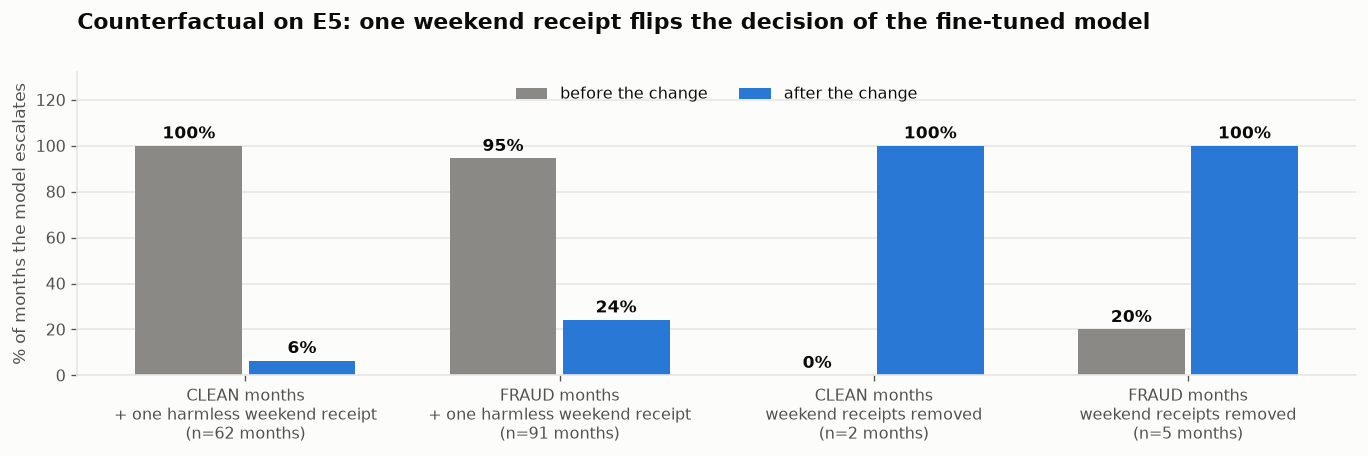

In [38]:
W = B["weekend_counterfactual"]
groups = [("clean|added", "CLEAN months\n+ one harmless weekend receipt"), ("fraud|added", "FRAUD months\n+ one harmless weekend receipt"), ("clean|removed", "CLEAN months\nweekend receipts removed"), ("fraud|removed", "FRAUD months\nweekend receipts removed")]
fig, ax = plt.subplots(figsize=(11.5, 3.9)); xs_ = np.arange(len(groups)); w = .34
b1 = ax.bar(xs_ - w / 2 - .01, [100 * W[g_]["before"] / W[g_]["n"] for g_, _ in groups], w, color=PAL["muted"], label="before the change"); b2 = ax.bar(xs_ + w / 2 + .01, [100 * W[g_]["after"] / W[g_]["n"] for g_, _ in groups], w, color=PAL["ft"], label="after the change")
dz.label_bars(ax, b1, "{:.0f}%", dy=1.5, fs=10); dz.label_bars(ax, b2, "{:.0f}%", dy=1.5, fs=10)
ax.set_xticks(xs_); ax.set_xticklabels([l + f"\n(n={W[g_]['n']} months)" for g_, l in groups], fontsize=9.5); ax.set_ylim(0, 132); ax.set_ylabel("% of months the model escalates"); ax.legend(loc="upper center", ncol=2)
ax.set_title("Counterfactual on E5: one weekend receipt flips the decision of the fine-tuned model", pad=26); plt.tight_layout(); plt.show()

In [39]:
dz.callout('bad', 'Change one harmless stationery receipt to a Saturday and the model stops escalating almost every clean month (100% → 6%) <b>and</b> almost every fraud month (95% → 24%). Remove the weekend receipts and it escalates everything again. Its decision depends on that single feature, so its real fraud detection on E5 is about 24% at 6% false alarms.', 'Shortcut confirmed')

In [40]:
h = "X0004"; print(B["text_E5"][h][:1800]); print("\n--- what the fine-tuned Qwen3-4B answered (this month is CLEAN, there is no fraud) ---"); print(B["tuned_reasons_E5"][h])
print("\n--- Sonnet 5.5 + 4 examples escalated:", E5["pred"]["Sonnet 5.5 agents + 4 examples"].get(h) or "nothing (correct)")

EMPLOYEE HISTORY X0004 (entity GLOBAL, all amounts in USD). Every receipt below was ALREADY checked by the deterministic engine and got verdict `pass`.

RECEIPTS (chronological):
- X0004-R01 | 2026-05-04 12:35 (Mon) | Sunrise Noodle House | Meals - Team | $52.50, 3 attendees | Pho bowls (x3) + Jasmine iced tea (x3)
- X0004-R02 | 2026-05-06 09:50 (Wed) | Inkwell Office Mart | Office Supplies | $15.78 | Legal pads yellow 6pk + Binder clips medium 24ct
- X0004-R03 | 2026-05-12 14:20 (Tue) | Bitforge Peripherals | Computer Equipment | $329.00, approval PA-2026-0388 | 27in 4K monitor, USB-C 90W
- X0004-R04 | 2026-05-18 06:55 (Mon) | Greenline Rides | Travel - Other | $39.80, TRIP-4472 (2 nights) | Ride home to airport
- X0004-R05 | 2026-05-18 19:40 (Mon) | Pike Street Bistro | Meals - Individual | $30.00, 1 attendees, TRIP-4472 (2 nights) | Roast chicken dinner + Club soda
- X0004-R06 | 2026-05-19 07:25 (Tue) | Early Bird Bakery | Meals - Individual | $10.25, 1 attendees, TRIP-4472 (2 night

### 8.5 Where each one fails (by scheme in E5)

In [41]:
fam = collections.defaultdict(lambda: [0, 0, 0])
sf = E5["pred"]["Sonnet 5.5 agents + 4 examples"]
for hid, k in key5.items():
    if k["kind"] != "E5_independent": continue
    pl = set(k["planted"]); f = fam[k["family"]]; f[0] += 1; f[1] += bool(pl & set(tun[hid])); f[2] += bool(pl & set(sf[hid]))

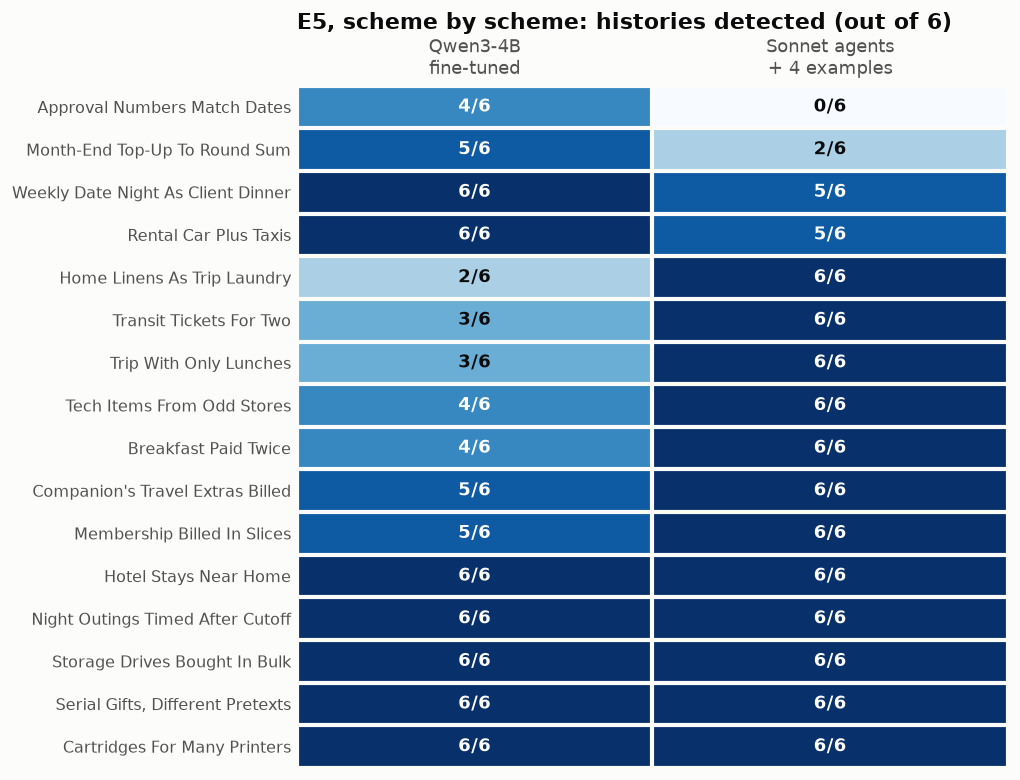

In [42]:
nm = {x["scheme"]: x["readable_name"] for x in json.load(open(DATA/"catalog_en.json"))}
rowsH = sorted(fam.items(), key=lambda kv: (kv[1][2], kv[1][1]))
M_ = np.array([[v[1], v[2]] for _, v in rowsH]); labs = [nm.get(k, k) for k, _ in rowsH]; N = rowsH[0][1][0]
fig, ax = plt.subplots(figsize=(8.6, 6.6)); im = ax.imshow(M_, cmap="Blues", vmin=0, vmax=N, aspect="auto")
for i in range(M_.shape[0]):
    for j in range(2): ax.text(j, i, f"{M_[i, j]}/{N}", ha="center", va="center", fontsize=10.5, fontweight="bold", color="white" if M_[i, j] > N * .55 else PAL["ink"])
ax.set_xticks([0, 1]); ax.set_xticklabels(["Qwen3-4B\nfine-tuned", "Sonnet agents\n+ 4 examples"], fontsize=10.5); ax.xaxis.tick_top(); ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs, fontsize=9.5)
ax.grid(False); [s_.set_visible(False) for s_ in ax.spines.values()]; ax.set_xticks(np.arange(-.5, 2), minor=True); ax.set_yticks(np.arange(-.5, len(labs)), minor=True); ax.grid(which="minor", color=PAL["surface"], lw=2.5); ax.tick_params(which="both", length=0)
ax.set_title("E5, scheme by scheme: histories detected (out of 6)", pad=34); plt.tight_layout(); plt.show()

### 8.6 A methodological warning: the call format matters as much as the model
We ran the frontier models in two ways: as **agents** (13 histories per file, multi-step reasoning) and through the **API with a single call per history**. With the *same* Sonnet 5.5, the difference is enormous:

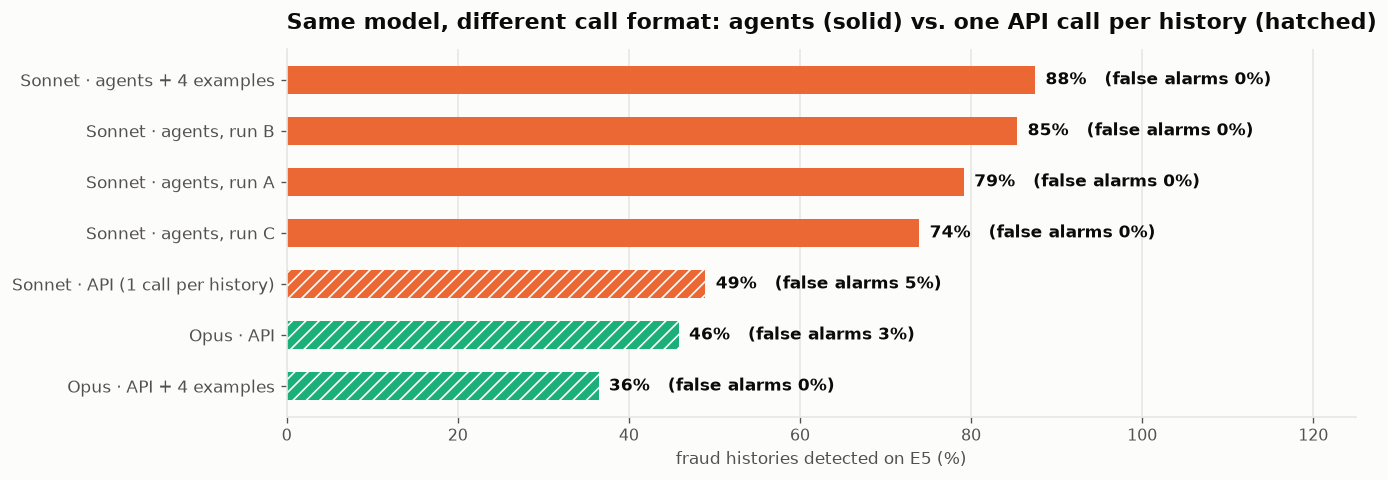

In [43]:
names = ["Sonnet 5.5 agents, run A", "Sonnet 5.5 agents, run B", "Sonnet 5.5 agents, run C", "Sonnet 5.5 agents + 4 examples", "Sonnet 5.5 API (1 call per history)", "Opus 4.5 API", "Opus 4.5 API + 4 examples"]
d = T5.loc[names, ["history recall", "false alarms"]].sort_values("history recall")
fig, ax = plt.subplots(figsize=(11.5, 4.1))
for i, (n, r) in enumerate(d.iterrows()):
    api = "API" in n; b = ax.barh(i, 100 * r["history recall"], .55, color=dz.entity_color(n), hatch="///" if api else None, edgecolor=PAL["surface"] if api else "none", linewidth=0)
    ax.text(100 * r["history recall"] + 1.2, i, f"{100*r['history recall']:.0f}%   (false alarms {100*r['false alarms']:.0f}%)", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(range(len(d))); ax.set_yticklabels([n.replace("Sonnet 5.5 ", "Sonnet · ").replace("Opus 4.5 ", "Opus · ") for n in d.index], fontsize=10); ax.set_xlim(0, 125); ax.set_xlabel("fraud histories detected on E5 (%)"); ax.grid(False); ax.xaxis.grid(True)
ax.set_title("Same model, different call format: agents (solid) vs. one API call per history (hatched)"); plt.tight_layout(); plt.show()

In [44]:
print('Variation across 3 identical Sonnet runs (agents): recall', [f"{T5.loc[k,'history recall']:.0%}" for k in ['Sonnet 5.5 agents, run A', 'Sonnet 5.5 agents, run B', 'Sonnet 5.5 agents, run C']])

Variation across 3 identical Sonnet runs (agents): recall ['79%', '85%', '74%']


**Consequences for what we can claim:**
1. We **cannot** say Opus 4.5 is worse than Sonnet 5.5. Through the API in a single call, Sonnet 5.5 (49%) and Opus 4.5 (46%) end up similar: the call format matters more than the model.
2. A single run of a frontier model **varies** (74–85% across three identical runs). Reporting a single run would be misleading.
3. With the same format (one call per history), the fine-tuned model has **more recall** (80% vs ~48%) but **97% false alarms** against 3–5%; a recall like that is useless in production.

In [45]:
dz.banner(9, 'Governance and cost: why was it worth trying our own model?', 'Is it governance, cost or quality that justifies an own model?')

The underlying motivation was **not to win a benchmark**: it was to be able to review patterns without depending on a third party. It is justified as follows:

| Criterion | Frontier model via API | Own model (local Qwen3-4B) |
|---|---|---|
| **Data** | every receipt goes out to a provider | **does not leave the machine** |
| **Version** | the provider retires models (e.g. Opus 4.5 is not retired before 2026-11-24) | **fixed weights**: same answer tomorrow and in a year |
| **Audit** | the provider's black box | weights, prompt and training data are **versionable** |
| **Marginal cost** | per token | **no cost per call** (hardware already bought) |
| **Latency** | not measured here | **measured: ~8 s per history** on a 16 GB Mac mini |
And what we **did** measure of the cost:

In [46]:
PRICE = {"Opus 4.5": (5, 25), "Sonnet 5.5": (2, 10), "Haiku 5.5": (0.10, 0.50)}   # USD per million tokens (input, output)
tk = B["tokens_api"]
def per_1000(tok, model):
    n = tok["n"]; pin, pout = PRICE[model]; return tok["in"] / n * 1000 / 1e6 * pin + tok["out"] / n * 1000 / 1e6 * pout
rows = [{"option": "Opus 4.5 via API (zero-shot)", "input tokens / history": tk["opus45zero"]["in"] / 160, "output tokens / history": tk["opus45zero"]["out"] / 160, "USD per 1,000 histories": per_1000(tk["opus45zero"], "Opus 4.5"), "source": "measured"},
        {"option": "Opus 4.5 via API (+4 examples)", "input tokens / history": tk["opus45fs"]["in"] / 160, "output tokens / history": tk["opus45fs"]["out"] / 160, "USD per 1,000 histories": per_1000(tk["opus45fs"], "Opus 4.5"), "source": "measured"},
        {"option": "Sonnet 5.5 via API (zero-shot, includes reasoning)", "input tokens / history": tk["sonnet55api"]["in"] / 160, "output tokens / history": tk["sonnet55api"]["out"] / 160, "USD per 1,000 histories": per_1000(tk["sonnet55api"], "Sonnet 5.5"), "source": "measured"},
        {"option": "Haiku 5.5 via API (same tokens as Sonnet without reasoning)", "input tokens / history": tk["sonnet55api"]["in"] / 160, "output tokens / history": 100, "USD per 1,000 histories": per_1000({"in": tk["sonnet55api"]["in"], "out": 100 * 160, "n": 160}, "Haiku 5.5"), "source": "estimated"},
        {"option": "Fine-tuned Qwen3-4B on the Mac mini", "input tokens / history": 1390, "output tokens / history": 100, "USD per 1,000 histories": 0.0, "source": "tokens: mean of the training data; no cost per call"}]
display(pd.DataFrame(rows).style.format({"input tokens / history": "{:,.0f}", "output tokens / history": "{:,.0f}", "USD per 1,000 histories": "${:,.2f}"}).hide(axis="index"))
print("Local Qwen latency (measured): ~7.8 s per history → 1,000 histories ≈ 2.2 h on a Mac mini. We did not measure API latency.")

option,input tokens / history,output tokens / history,"USD per 1,000 histories",source
Opus 4.5 via API (zero-shot),"1,516",68,$9.27,measured
Opus 4.5 via API (+4 examples),"5,983",64,$31.51,measured
"Sonnet 5.5 via API (zero-shot, includes reasoning)","1,966",491,$8.84,measured
Haiku 5.5 via API (same tokens as Sonnet without reasoning),"1,966",100,$0.25,estimated
Fine-tuned Qwen3-4B on the Mac mini,"1,390",100,$0.00,tokens: mean of the training data; no cost per call


Local Qwen latency (measured): ~7.8 s per history → 1,000 histories ≈ 2.2 h on a Mac mini. We did not measure API latency.


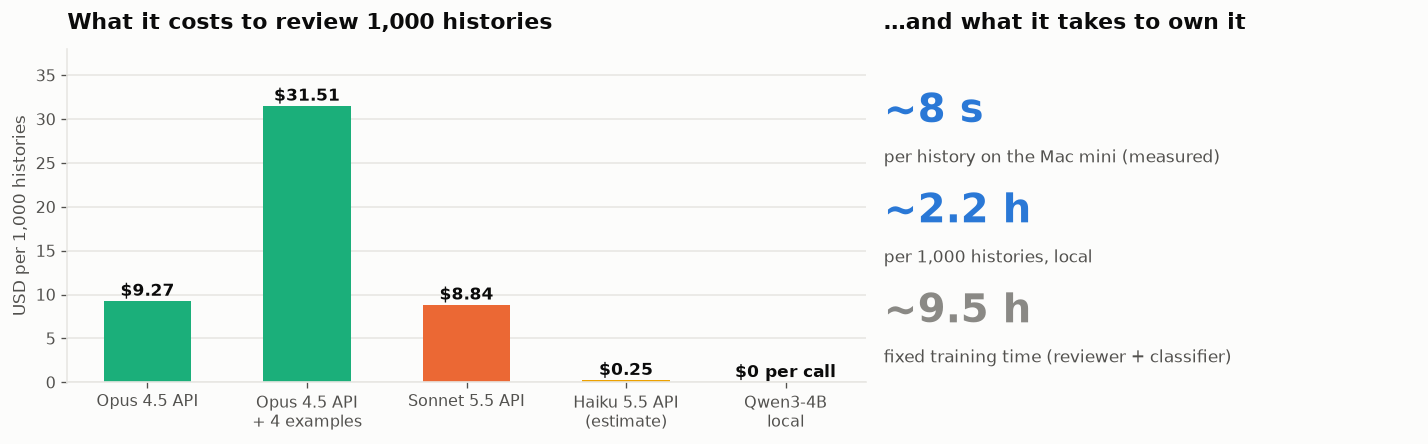

In [47]:
dfc = pd.DataFrame(rows); dfc["short"] = ["Opus 4.5 API", "Opus 4.5 API\n+ 4 examples", "Sonnet 5.5 API", "Haiku 5.5 API\n(estimate)", "Qwen3-4B\nlocal"]
colc = [PAL["opus"], PAL["opus"], PAL["sonnet"], PAL["haiku"], PAL["ft"]]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
b = ax[0].bar(dfc["short"], dfc["USD per 1,000 histories"], color=colc, width=.55); ax[0].set_ylabel("USD per 1,000 histories"); ax[0].set_title("What it costs to review 1,000 histories")
for bar, v in zip(b, dfc["USD per 1,000 histories"]): ax[0].text(bar.get_x() + bar.get_width() / 2, v + .6, f"${v:,.2f}" if v else "$0 per call", ha="center", fontsize=10, fontweight="bold")
ax[0].grid(False); ax[0].yaxis.grid(True); ax[0].set_ylim(0, 38)
ax[1].axis("off"); ax[1].set_title("…and what it takes to own it")
for k, (t, v, c_) in enumerate([("~8 s", "per history on the Mac mini (measured)", PAL["ft"]), ("~2.2 h", "per 1,000 histories, local", PAL["ft"]), ("~9.5 h", "fixed training time (reviewer + classifier)", PAL["muted"])]):
    ax[1].text(0, .78 - k * .3, t, fontsize=24, fontweight="bold", color=c_, transform=ax[1].transAxes); ax[1].text(0, .66 - k * .3, v, fontsize=10, color=PAL["ink2"], transform=ax[1].transAxes)
plt.tight_layout(); plt.show()

**Fixed cost of the own model (honest):** ~5 h of reviewer training and ~4.5 h of classifier training on the mini, plus generating the data with frontier models (tokens not added up) and engineering time. With prices of **~<span class="tex2jax_ignore">&#36;</span>9 per 1,000 histories** via API, per-token savings **do not justify** an own model on their own at our volume; what justifies trying it is **control** (data, version, audit), not money.

**Governance: what is promised vs. what the tests show.** The benefits in the table above are **deployment properties**, not measured quality results. Our tests say that **today** the own model does not reach the quality needed to take advantage of them.

In [48]:
dz.banner(10, 'Honest conclusions and what comes next', 'What is true, what is not, what comes next')

In [49]:
dz.cards([('Demonstrated', 'The engine solves the task', '32/32 decisions reproduced. Every verdict cites a rule and numbers. Its limit is real: one receipt at a time.', '#0a7a0a'), ('Demonstrated', 'An LLM reviewer catches what rules cannot', 'Sonnet 5.5 + 4 examples: ~88% recall and 0% false alarms on an independent set.', '#0a7a0a'), ('Not demonstrated', 'An own 4B model beating a frontier model', 'It won on our own exams but lost on E5: it learned the generator style (97% false alarms).', '#d03b3b'), ('Next', 'Train on several authors, test on a fresh set', 'Diverse clean months, hard negatives, dollar weighting, several seeds.', '#6250d6')])

**What was demonstrated**

1. The deterministic engine solves the task (32/32 reproducible, every decision cites the rule and the numbers) and has a **real, documented limit**: it does not see patterns across receipts.
2. **An LLM as a second-line reviewer** (it only escalates, the engine decides) **does catch** those frauds on data it never saw: Sonnet 5.5 with 4 examples ≈ 88% recall with 0% false alarms on E5.
3. There is a rigorous evaluation method (frozen criteria, independent set, deterministic score, confidence intervals) and a catalog of **72 patterns** verified with the real engine.

**What was NOT demonstrated (and why it matters to say so)**

4. **"An own Qwen3-4B beats a frontier model": no.** It won on our own benchmark (E1–E4) but **lost on E5**: it learned a shortcut in our own synthetic data (weekend receipts), so even its E1–E4 numbers are probably inflated. It is a useful negative result, not a failure of the method.
5. We did not measure API latency or the total cost of building the own model.

**What it would take to try again (in this order)**

| Step | Why |
|---|---|
| **Training data from several authors and styles**, with diverse clean months | the cause of the failure was a single generator |
| **Hard negatives:** clean months that *look like* patterns (a normal trip, a one-off gift) | so it learns to abstain |
| **A new test set (E6) never seen even by us** before training | E5 has already been used to diagnose |
| **Dollar weighting** and more examples of `pa_reuse` and `weekend_stay_beyond_trip` | that is where the money and the failures are |
| **Several seeds** and reporting the range | today it is a single run |
| **RLVR (GRPO)** with a deterministic reward per receipt and per dollar | the industry case study's method |

**Recommendation for the presentation:** open with the engine and its limit, show the pattern catalog and the frontier results (the practical proposal today), and present the fine-tuning as a **rigorous experiment with a clear lesson**: without data from several authors, the own model does not generalize. That is more credible than promising a victory that the independent test does not support.